# Basel III Endgame Credit Capital for U.S. Banks: the Standardised Approach versus Foundation and Advanced IRB, the 72.5% Output Floor, and How Machine-Learning PDs Move Risk-Weighted Assets

Basel III's final reform, called the "endgame" in the United States, changes how banks turn credit risk into capital. Large banks may use their own models of the probability of default (PD) and loss given default (LGD), the internal-ratings-based (IRB) approaches, but their risk-weighted assets (RWA) can no longer fall below 72.5% of what the new standardised approach would give. This notebook rebuilds the credit RWA of the loan book of every U.S. bank from public call-report data under four rules: today's U.S. standardised approach, the Basel III standardised approach (SA-CR), foundation IRB and advanced IRB. It then asks how much the floor binds and how much the choice of PD model, logistic regression or gradient boosting, moves capital.

**What it does.**

1. It reads year-end call reports from 2001 to 2025 for every FDIC-insured bank: loans by type (residential mortgages, home-equity lines, construction, commercial real estate, multifamily, farmland, commercial and industrial, credit cards, auto and other consumer, agricultural), noncurrent loans and net charge-offs by type, risk-weighted assets and CET1 capital.
2. It measures each bank's annual **default rate** by loan type (loans 90 days past due or on non-accrual at year-end plus the year's net charge-offs, relative to the book) and the **loss given default** of each loan type (net charge-offs relative to that default measure).
3. It forecasts next year's default rate for every bank and loan type with a persistence rule, a fractional logistic regression and LightGBM, trained on earlier years and tested out of time from 2008.
4. It computes credit RWA with the U.S. standardised weights, the Basel III SA-CR weights, and the IRB formulas, with long-run average (through-the-cycle) PDs and with point-in-time PDs from each model. The 72.5% output floor is applied to the IRB results.
5. It shows the effect on the largest banks' CET1 ratios, and how procyclical capital becomes when PDs follow the cycle.

**Data.** FDIC call reports through the BankFind Suite API (financial data for every insured bank); unemployment rate, house prices and the federal funds rate (FRED).

**Methods.** Basel III standardised risk weights, the IRB asymptotic single-risk-factor formula with supervisory correlations and maturity adjustment, Basel III PD and LGD input floors, the output floor, fractional logistic regression, LightGBM with expanding-window out-of-time tests, and cyclicality analysis.

**Key output.** Credit RWA density by approach and bank size; the share of banks for which the floor binds; pro forma CET1 ratios of the largest banks; the accuracy of the PD forecasts; and the swing in IRB capital over the cycle.

## 1. From PD to capital

**The IRB formula.** For an exposure with probability of default PD, loss given default LGD and exposure at default EAD, the capital requirement per unit of exposure is the loss in a one-in-a-thousand-year downturn minus the expected loss:

*K* = LGD × [ Φ( (Φ⁻¹(PD) + √R Φ⁻¹(0.999)) / √(1 − R) ) − PD ] × MA,

and RWA = 12.5 × *K* × EAD. R is the **asset correlation**, which Basel sets by asset class:
- corporates: 12–24%, falling as PD rises;
- residential mortgages: 15%;
- qualifying revolving retail (credit cards): 4%;
- other retail: 3–16%.

MA is a maturity adjustment for corporates (with a 2.5-year maturity here) and 1 for retail.

**Foundation versus advanced.** Under foundation IRB the bank estimates only PD; LGD is supervisory: 40% for senior unsecured corporate exposures, lower when secured by real estate. Under advanced IRB the bank also estimates LGD and EAD. Retail exposures have no foundation approach. Basel III adds input floors: PD of at least 0.05% (0.10% for credit-card revolvers), and LGD of at least 25% for unsecured corporates, 5% for residential mortgages, 50% for credit cards and 30% for other unsecured retail.

**The standardised approaches.** U.S. banks today use the U.S. standardised approach, with fixed weights: 50% for prudent first-lien mortgages and 100% for most other loans. Basel III's SA-CR is more risk-sensitive: 20–70% for residential mortgages by loan-to-value, 75% for regulatory retail, 85% for small-business corporates, and 150% for land acquisition, development and construction.

**The output floor.** Total IRB RWA must be at least 72.5% of SA-CR RWA. It limits how far internal models can lower capital.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
from scipy.stats import norm, spearmanr

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2017
FDIC_API = "https://api.fdic.gov/banks"
YEARS = range(2001, 2026)
FLOOR = 0.725
TEST_FROM = 2008

print(f"lightgbm {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · run on 2026-11-04


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. The data: loan books, defaults and losses

Each loan type in the call report has three items: the balance (`LN…`), loans 90 days or more past due plus non-accrual loans (`NC…`), and net charge-offs over the year (`NT…`). They are mapped to Basel asset classes. Net charge-offs are reported year to date, so the December figure is the full year.

In [3]:
TYPES = {  # call-report suffix: (label, Basel III asset class)
    "RERES": ("residential mortgages", "residential"),
    "RELOC": ("home-equity lines", "residential"),
    "RECONS": ("construction and land", "ADC"),
    "RENRES": ("commercial real estate", "CRE"),
    "REMULT": ("multifamily", "CRE"),
    "REAG": ("farmland", "corporate"),
    "CI": ("commercial and industrial", "corporate"),
    "AG": ("agricultural", "corporate"),
    "CRCD": ("credit cards", "QRRE"),
    "AUTO": ("auto", "other retail"),
    "CONOTH": ("other consumer", "other retail"),
}
FIELDS = [
    "CERT",
    "REPDTE",
    "NAME",
    "STNAME",
    "ASSET",
    "RBCT1J",
    "RWAJ",
    "RBCT1CER",
    "LNLSGR",
    "UC",
] + [f"{p}{s}" for s in TYPES for p in ("LN", "NC", "NT")]


def fetch_year(y):
    rows, offset = [], 0
    while True:
        r = requests.get(
            f"{FDIC_API}/financials",
            timeout=180,
            params={
                "filters": f"REPDTE:{y}1231",
                "fields": ",".join(FIELDS),
                "limit": 10000,
                "offset": offset,
                "format": "json",
            },
        )
        r.raise_for_status()
        j = r.json()
        rows += [d["data"] for d in j["data"]]
        offset += len(j["data"])
        if offset >= j["meta"]["total"] or not j["data"]:
            break
    return pd.DataFrame(rows)


CALL = cached(
    "fdic_yearend_2001_2025",
    lambda: pd.concat([fetch_year(y) for y in YEARS], ignore_index=True),
    max_age_hours=24 * 30,
)
CALL["year"] = CALL["REPDTE"].astype(str).str[:4].astype(int)
num = [c for c in FIELDS if c not in ("CERT", "REPDTE", "NAME", "STNAME")]
CALL[num] = CALL[num].apply(pd.to_numeric, errors="coerce")
dollars = [c for c in num if c != "RBCT1CER"]
# thousands of dollars → dollars
CALL[dollars] = CALL[dollars] * 1e3
# long panel: one row per bank, year and loan type
long = []
for s, (label, cls) in TYPES.items():
    x = CALL[["CERT", "NAME", "year", "ASSET"]].copy()
    x["type"], x["class"] = label, cls
    x["loans"], x["noncurrent"], x["chargeoffs"] = (
        CALL[f"LN{s}"],
        CALL[f"NC{s}"],
        CALL[f"NT{s}"],
    )
    long.append(x)
L = pd.concat(long, ignore_index=True)
L = (
    L[L["loans"] > 0]
    .sort_values(["CERT", "type", "year"])
    .reset_index(drop=True)
)
L["default rate"] = (
    (L["noncurrent"] + L["chargeoffs"].clip(lower=0)) / L["loans"]
).clip(0, 1)
g = L.groupby(["CERT", "type"])
L["next default rate"] = (
    g["default rate"].shift(-1).where(g["year"].shift(-1) == L["year"] + 1)
)
L["loan growth"] = (L["loans"] / g["loans"].shift(1) - 1).clip(-1, 5)
L["chargeoff rate"] = (L["chargeoffs"] / L["loans"]).clip(-0.1, 1)
last = CALL["year"].max()
print(
    f"{CALL['CERT'].nunique():,} banks, {CALL['year'].min()}–{last};"
    f" {len(L):,} bank-year-loan-type rows; loans at end-{last}:"
    f" ${L.loc[L['year'] == last, 'loans'].sum() / 1e12:,.1f} trillion"
)
mix = (
    L[L["year"] == last]
    .groupby("type")["loans"]
    .sum()
    .sort_values(ascending=False)
    / 1e9
)
mix.to_frame("loans ($bn)").style.format("{:,.0f}")

10,909 banks, 2001–2025; 1,415,224 bank-year-loan-type rows; loans at end-2025: $11.0 trillion


,loans ($bn)
type,
residential mortgages,"2,940"
commercial and industrial,"2,465"
commercial real estate,"1,915"
credit cards,"1,204"
multifamily,662
auto,536
construction and land,461
other consumer,317
home-equity lines,300


### Default rates and loss given default over the cycle

The **default rate** of a book in a year is the noncurrent loans at year-end plus the net charge-offs taken during the year, divided by the loans outstanding. Mortgages and commercial loans stay noncurrent for months before they are resolved, so the year-end stock captures most of their defaults; credit cards and other consumer loans are charged off quickly, so their defaults show up mostly as charge-offs. **LGD** for each loan type is the net charge-offs divided by the same default measure (noncurrent plus charged-off loans), pooled over all banks and years.

In [4]:
tot = L.groupby(["year", "type"])[["loans", "noncurrent", "chargeoffs"]].sum()
DR_SYS = (
    (tot["noncurrent"] + tot["chargeoffs"].clip(lower=0)) / tot["loans"]
).unstack()
pos = (
    L.assign(co=L["chargeoffs"].clip(lower=0))
    .groupby("type")[["co", "noncurrent"]]
    .sum()
)
LGD_EST = (pos["co"] / (pos["noncurrent"] + pos["co"])).clip(0.05, 0.95)
LR_PD = DR_SYS.mean()
TABLE = pd.DataFrame({
    "long-run default rate": LR_PD,
    "peak default rate": DR_SYS.max(),
    "peak year": DR_SYS.idxmax(),
    "estimated LGD": LGD_EST,
})
display(
    TABLE.sort_values("long-run default rate", ascending=False).style.format({
        "long-run default rate": "{:.2%}",
        "peak default rate": "{:.2%}",
        "estimated LGD": "{:.0%}",
    })
)
DR_SYS.loc[[2001, 2006, 2009, 2010, 2015, 2020, 2021, last]].style.format(
    "{:.2%}"
)

,long-run default rate,peak default rate,peak year,estimated LGD
type,,,,
credit cards,5.94%,12.50%,2009,71%
construction and land,4.24%,22.52%,2010,22%
residential mortgages,3.42%,9.65%,2009,12%
other consumer,2.61%,4.99%,2011,61%
home-equity lines,2.20%,5.03%,2012,34%
commercial and industrial,1.91%,6.00%,2009,35%
commercial real estate,1.61%,5.51%,2010,15%
farmland,1.44%,3.11%,2010,7%
auto,1.14%,1.87%,2024,59%


type,agricultural,auto,commercial and industrial,commercial real estate,construction and land,credit cards,farmland,home-equity lines,multifamily,other consumer,residential mortgages
year,,,,,,,,,,,
2001,0.96%,nan%,3.85%,1.13%,1.24%,7.11%,1.65%,0.55%,0.43%,2.37%,0.99%
2006,0.21%,nan%,0.94%,0.65%,0.85%,5.26%,0.71%,0.53%,0.58%,1.93%,1.01%
2009,1.47%,nan%,6.00%,4.61%,22.03%,12.50%,2.67%,4.80%,5.52%,4.82%,9.65%
2010,2.02%,nan%,4.15%,5.51%,22.52%,11.44%,3.11%,4.57%,5.02%,3.74%,9.41%
2015,0.21%,0.86%,1.02%,0.92%,1.11%,3.90%,1.03%,2.97%,0.28%,2.17%,4.11%
2020,0.40%,1.18%,1.51%,1.12%,0.68%,4.76%,1.72%,2.11%,0.27%,1.84%,2.50%
2021,0.25%,0.69%,0.86%,0.74%,0.48%,2.85%,1.16%,2.09%,0.26%,1.23%,2.04%
2025,0.19%,1.63%,1.51%,1.51%,1.00%,5.54%,0.78%,1.54%,1.16%,2.21%,1.34%


## 4. Forecasting next year's default rate

For each bank and loan type, the target is next year's default rate. The features are known at year-end: the current default rate and charge-off rate, loan growth, the loan type's share of the bank's book, bank size, and the national unemployment rate, house-price growth and federal funds rate. Three forecasts are compared out of time: each test year from 2008 uses models trained on all earlier years.
- **Persistence:** next year's rate equals this year's.
- **Fractional logistic regression** (Papke and Wooldridge, 1996): a logit model of the fraction defaulted, weighted by loan balance.

Models are trained on books of at least \$10 million, where a single loan does not decide the rate; smaller books get their bank's long-run average or the system rate when capital is computed.
- **LightGBM** with a cross-entropy objective on the same fraction and weights.

Accuracy is measured on loan-weighted errors and by the rank correlation across bank-loan-type cells, which is what decides which banks get more capital.

In [5]:
def macro():
    m = pd.DataFrame({
        "unemployment": fred.get_series("UNRATE"),
        "house prices": fred.get_series("USSTHPI"),
        "fed funds": fred.get_series("FEDFUNDS"),
    })
    q4 = m.resample("QE").last()
    q4 = q4[q4.index.month == 12]
    out = pd.DataFrame({
        "unemployment": q4["unemployment"],
        "house price growth": (
            q4["house prices"].pct_change(4, fill_method=None)
        ),
        "fed funds": q4["fed funds"],
    })
    out.index = out.index.year
    return out


MAC = macro()
L = L.merge(MAC, left_on="year", right_index=True, how="left")
L["book share"] = L["loans"] / L.groupby(["CERT", "year"])["loans"].transform(
    "sum"
)
L["log assets"] = np.log(L["ASSET"])
L["type code"] = L["type"].astype("category").cat.codes
FEATS = [
    "default rate",
    "chargeoff rate",
    "loan growth",
    "book share",
    "log assets",
    "unemployment",
    "house price growth",
    "fed funds",
    "type code",
]
# books of at least $10m
D = (
    L[L["loans"] >= 10e6]
    .dropna(subset=["next default rate"] + FEATS[:-1])
    .copy()
)
D[FEATS[:-1]] = D[FEATS[:-1]].astype("float32")
D["w"] = D["loans"] / D.groupby("year")["loans"].transform("sum")
types_d = pd.get_dummies(D["type"], prefix="t", drop_first=True, dtype=float)
XG = pd.concat([D[FEATS[:-1]], types_d], axis=1)
XG["default rate"] = np.log(D["default rate"] + 1e-4)
XG["chargeoff rate"] = D["chargeoff rate"].clip(-0.02, 0.3)


def frac_logit(X, y, w, iters=25, ridge=1e-6):
    """
    Weighted fractional logistic regression (Papke–Wooldridge quasi-likelihood)
    fitted by IRLS.
    """
    X = np.column_stack([np.ones(len(X)), np.asarray(X, dtype=float)])
    mu_x, sd_x = X[:, 1:].mean(0), X[:, 1:].std(0) + 1e-12
    X[:, 1:] = (X[:, 1:] - mu_x) / sd_x
    b = np.zeros(X.shape[1])
    b[0] = np.log(np.average(y, weights=w) / (1 - np.average(y, weights=w)))
    for _ in range(iters):
        p = 1 / (1 + np.exp(-(X @ b)))
        W = w * p * (1 - p)
        H = (X * W[:, None]).T @ X + ridge * np.eye(X.shape[1])
        step = np.linalg.solve(H, X.T @ (w * (y - p)))
        b += step
        if np.abs(step).max() < 1e-8:
            break
    return lambda Z: 1 / (
        1
        + np.exp(
            -(
                np.column_stack([
                    np.ones(len(Z)),
                    (np.asarray(Z, dtype=float) - mu_x) / sd_x,
                ])
                @ b
            )
        )
    )


preds = []
for yr in range(TEST_FROM, int(D["year"].max()) + 1):
    tr, te = (D["year"] < yr).to_numpy(), (D["year"] == yr).to_numpy()
    glm = frac_logit(
        XG[tr],
        D.loc[tr, "next default rate"].to_numpy(),
        D.loc[tr, "w"].to_numpy(),
    )
    gbm = lgb.LGBMRegressor(
        objective="cross_entropy",
        n_estimators=400,
        learning_rate=0.03,
        num_leaves=31,
        min_child_samples=200,
        subsample=0.8,
        subsample_freq=1,
        random_state=SEED,
        verbose=-1,
    ).fit(
        D.loc[tr, FEATS],
        D.loc[tr, "next default rate"],
        sample_weight=D.loc[tr, "w"],
    )
    p = D.loc[
        te,
        [
            "CERT",
            "type",
            "year",
            "loans",
            "w",
            "next default rate",
            "default rate",
        ],
    ].copy()
    p["persistence"] = p["default rate"]
    p["logistic regression"] = glm(XG[te])
    p["LightGBM"] = gbm.predict(D.loc[te, FEATS])
    preds.append(p)
PRED = pd.concat(preds, ignore_index=True)
MODELS = ["persistence", "logistic regression", "LightGBM"]


def scores(d):
    y, w = d["next default rate"], d["loans"]
    return pd.Series({
        **{
            f"MAE {m}": np.average((d[m] - y).abs(), weights=w) * 100
            for m in MODELS
        },
        **{f"rank corr {m}": spearmanr(d[m], y).statistic for m in MODELS},
        **{
            f"system rate error {m}": (
                (np.average(d[m], weights=w) - np.average(y, weights=w)) * 100
            )
            for m in MODELS
        },
    })


BY_YEAR = PRED.groupby("year").apply(scores)
BY_YEAR.index = (BY_YEAR.index + 1).rename("forecast year")
OVERALL = scores(PRED)
print(
    f"forecasts for {PRED['year'].min() + 1}–{PRED['year'].max() + 1}:"
    f" {len(PRED):,} bank-loan-type-years"
)
display(OVERALL.to_frame("all test years").T.style.format("{:.3f}"))
BY_YEAR[[f"system rate error {m}" for m in MODELS]].style.format("{:+.2f}")

forecasts for 2009–2025: 339,838 bank-loan-type-years


,MAE persistence,MAE logistic regression,MAE LightGBM,rank corr persistence,rank corr logistic regression,rank corr LightGBM,system rate error persistence,system rate error logistic regression,system rate error LightGBM
all test years,1.066,3.536,1.660,0.726,0.716,0.629,-0.070,2.936,0.739


,system rate error persistence,system rate error logistic regression,system rate error LightGBM
forecast year,,,
2009,-4.55,+2.27,-3.77
2010,+0.02,+34.94,+4.98
2011,+0.80,+10.18,+1.02
2012,+0.35,+5.46,+1.12
2013,+1.22,+2.38,+4.59
2014,+0.75,+1.33,+2.79
2015,+0.39,+0.57,+1.79
2016,+0.07,+0.13,+1.17
2017,+0.17,+0.24,+0.23


## 5. Credit RWA under four rules

RWA is computed for the on-balance-sheet loan book of every bank at the end of the latest year. Undrawn commitments, securities, derivatives and operational risk are left out; the last section compares the loan book with each bank's reported total RWA.

**Weights used.**

| Loan type | U.S. standardised | Basel III SA-CR | IRB asset class | Foundation LGD |
|---|---|---|---|---|
| Residential mortgages | 50% | 30% (LTV 60–80%) | residential, R = 15% | bank estimate (retail) |
| Home-equity lines | 100% | 75% | residential, R = 15% | bank estimate (retail) |
| Construction and land | 150% | 150% | corporate | 25% |
| Commercial real estate, multifamily | 100% | 100% | corporate | 25% |
| C&I, agricultural, farmland | 100% | 85% (SME corporate) | corporate | 40% |
| Credit cards | 100% | 75% | QRRE, R = 4% | bank estimate (retail) |
| Auto and other consumer | 100% | 75% | other retail | bank estimate (retail) |

Under **advanced IRB** the LGD of every class is the estimated LGD of section 3, subject to the Basel III floors. PDs are either the bank's own **long-run average** default rate for each loan type (through the cycle, at least five years of data, otherwise the system average) or the **point-in-time** forecast of each model.

In [6]:
US_SA = {
    "residential mortgages": 0.5,
    "home-equity lines": 1.0,
    "construction and land": 1.5,
    "commercial real estate": 1.0,
    "multifamily": 1.0,
    "farmland": 1.0,
    "commercial and industrial": 1.0,
    "agricultural": 1.0,
    "credit cards": 1.0,
    "auto": 1.0,
    "other consumer": 1.0,
}
B3_SA = {
    "residential mortgages": 0.30,
    "home-equity lines": 0.75,
    "construction and land": 1.5,
    "commercial real estate": 1.0,
    "multifamily": 1.0,
    "farmland": 0.85,
    "commercial and industrial": 0.85,
    "agricultural": 0.85,
    "credit cards": 0.75,
    "auto": 0.75,
    "other consumer": 0.75,
}
F_LGD = {"ADC": 0.25, "CRE": 0.25, "corporate": 0.40}
LGD_FLOOR = {
    "residential": 0.05,
    "QRRE": 0.50,
    "other retail": 0.30,
    "corporate": 0.25,
    "CRE": 0.10,
    "ADC": 0.10,
}
PD_FLOOR = {"QRRE": 0.001}


def irb_k(pd_, lgd, cls, m=2.5):
    pd_ = np.clip(pd_, PD_FLOOR.get(cls, 0.0005), 0.9999)
    if cls == "residential":
        r = 0.15
    elif cls == "QRRE":
        r = 0.04
    elif cls == "other retail":
        e = (1 - np.exp(-35 * pd_)) / (1 - np.exp(-35))
        r = 0.03 * e + 0.16 * (1 - e)
    else:
        e = (1 - np.exp(-50 * pd_)) / (1 - np.exp(-50))
        r = 0.12 * e + 0.24 * (1 - e)
    k = lgd * (
        norm.cdf(
            (norm.ppf(pd_) + np.sqrt(r) * norm.ppf(0.999)) / np.sqrt(1 - r)
        )
        - pd_
    )
    if cls in ("corporate", "CRE", "ADC"):
        b = (0.11852 - 0.05478 * np.log(pd_)) ** 2
        k = k * (1 + (m - 2.5) * b) / (1 - 1.5 * b)
    return np.maximum(k, 0)


def rwa_table(book, pd_col):
    b = book.copy()
    b["US SA"] = b["loans"] * b["type"].map(US_SA)
    b["Basel III SA"] = b["loans"] * b["type"].map(B3_SA)
    # retail has no foundation LGD
    f_lgd = b["class"].map(F_LGD).fillna(b["type"].map(LGD_EST))
    a_lgd = np.maximum(b["type"].map(LGD_EST), b["class"].map(LGD_FLOOR))
    f_lgd = np.where(
        b["class"].isin(["residential", "QRRE", "other retail"]), a_lgd, f_lgd
    )
    b["F-IRB"] = [
        12.5 * irb_k(p, l, c) * x
        for p, l, c, x in zip(b[pd_col], f_lgd, b["class"], b["loans"])
    ]
    b["A-IRB"] = [
        12.5 * irb_k(p, l, c) * x
        for p, l, c, x in zip(b[pd_col], a_lgd, b["class"], b["loans"])
    ]
    return b


bank_lr = L.groupby(["CERT", "type"]).agg(
    lr_pd=("default rate", "mean"), n=("default rate", "size")
)
book = L[L["year"] == last][
    ["CERT", "NAME", "ASSET", "type", "class", "loans", "default rate"]
].merge(bank_lr, on=["CERT", "type"], how="left")
book["TTC PD"] = np.where(
    book["n"] >= 5, book["lr_pd"], book["type"].map(LR_PD)
)
# point-in-time PDs for the coming year: models refit on all years with a known
# outcome
glm_f = frac_logit(XG, D["next default rate"].to_numpy(), D["w"].to_numpy())
gbm_f = lgb.LGBMRegressor(
    objective="cross_entropy",
    n_estimators=400,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=200,
    subsample=0.8,
    subsample_freq=1,
    random_state=SEED,
    verbose=-1,
).fit(D[FEATS], D["next default rate"], sample_weight=D["w"])
cur = L[L["year"] == last].dropna(subset=FEATS[:-1]).copy()
cur[FEATS[:-1]] = cur[FEATS[:-1]].astype("float32")
xc = pd.concat(
    [cur[FEATS[:-1]], pd.get_dummies(cur["type"], prefix="t", dtype=float)],
    axis=1,
).reindex(columns=XG.columns, fill_value=0)
xc["default rate"] = np.log(cur["default rate"] + 1e-4)
xc["chargeoff rate"] = cur["chargeoff rate"].clip(-0.02, 0.3)
cur["PIT PD logistic"] = glm_f(xc)
cur["PIT PD LightGBM"] = gbm_f.predict(cur[FEATS])
book = book.merge(
    cur[["CERT", "type", "PIT PD logistic", "PIT PD LightGBM"]],
    on=["CERT", "type"],
    how="left",
)
for c in ["PIT PD logistic", "PIT PD LightGBM"]:
    book[c] = book[c].fillna(book["TTC PD"])
APPROACH = {}
for pdc in ["TTC PD", "PIT PD logistic", "PIT PD LightGBM"]:
    t = rwa_table(book, pdc)
    APPROACH[pdc] = t.groupby(["CERT", "NAME", "ASSET"])[
        ["loans", "US SA", "Basel III SA", "F-IRB", "A-IRB"]
    ].sum()
B = APPROACH["TTC PD"].copy()
for pdc in ["PIT PD logistic", "PIT PD LightGBM"]:
    B[f"A-IRB ({pdc.replace('PIT PD ', 'PIT, ')})"] = APPROACH[pdc]["A-IRB"]
for c in ["F-IRB", "A-IRB", "A-IRB (PIT, logistic)", "A-IRB (PIT, LightGBM)"]:
    B[f"{c} floored"] = np.maximum(B[c], FLOOR * B["Basel III SA"])
B = B.reset_index()
B["size"] = pd.cut(
    B["ASSET"],
    [0, 1e9, 10e9, 100e9, np.inf],
    labels=["<$1bn", "$1–10bn", "$10–100bn", ">$100bn"],
)
cols = [
    "US SA",
    "Basel III SA",
    "F-IRB",
    "A-IRB",
    "A-IRB (PIT, logistic)",
    "A-IRB (PIT, LightGBM)",
    "F-IRB floored",
    "A-IRB floored",
]
DENSITY = (
    B.groupby("size", observed=True)[cols]
    .sum()
    .div(B.groupby("size", observed=True)["loans"].sum(), axis=0)
)
DENSITY.loc["all banks"] = B[cols].sum() / B["loans"].sum()
BIND = pd.Series({
    c: (B[c] < FLOOR * B["Basel III SA"]).mean()
    for c in [
        "F-IRB",
        "A-IRB",
        "A-IRB (PIT, logistic)",
        "A-IRB (PIT, LightGBM)",
    ]
})
big = B["size"] == ">$100bn"
BIND_BIG = pd.Series({
    c: (B.loc[big, c] < FLOOR * B.loc[big, "Basel III SA"]).mean()
    for c in BIND.index
})
print(
    f"end-{last}: {len(B):,} banks, ${B['loans'].sum() / 1e12:,.1f}tn of"
    " loans; floor binds for "
    + ", ".join(f"{k} {v:.0%}" for k, v in BIND.items())
    + " of banks; for banks over $100bn: "
    + ", ".join(f"{k} {v:.0%}" for k, v in BIND_BIG.items())
)
DENSITY.style.format("{:.1%}")

end-2025: 4,317 banks, $11.0tn of loans; floor binds for F-IRB 82%, A-IRB 94%, A-IRB (PIT, logistic) 95%, A-IRB (PIT, LightGBM) 96% of banks; for banks over $100bn: F-IRB 23%, A-IRB 35%, A-IRB (PIT, logistic) 23%, A-IRB (PIT, LightGBM) 32%


,US SA,Basel III SA,F-IRB,A-IRB,"A-IRB (PIT, logistic)","A-IRB (PIT, LightGBM)",F-IRB floored,A-IRB floored
size,,,,,,,,
<$1bn,88.6%,77.4%,42.3%,32.5%,25.1%,29.5%,57.5%,56.5%
$1–10bn,91.6%,81.8%,47.8%,37.2%,33.9%,34.1%,61.9%,60.7%
$10–100bn,91.1%,80.2%,51.8%,41.8%,42.2%,39.3%,62.5%,60.6%
>$100bn,87.0%,69.6%,70.1%,63.7%,62.7%,58.4%,70.6%,64.5%
all banks,88.7%,74.4%,60.7%,52.6%,51.1%,48.4%,66.6%,62.5%


## 6. The largest banks: pro forma CET1 ratios

For banks with more than \$100 billion of assets, the loan book's RWA under the U.S. standardised weights is replaced by its RWA under each new rule, keeping the rest of reported RWA (securities, off-balance-sheet, market and operational risk as measured today). The CET1 ratio is recomputed with the reported CET1 capital.

In [7]:
cap = CALL[CALL["year"] == last][["CERT", "RWAJ", "RBCT1CER"]]
G = B[big].merge(cap, on="CERT")
G["CET1"] = G["RBCT1CER"] / 100 * G["RWAJ"]
G["loan share of RWA"] = G["US SA"] / G["RWAJ"]
PRO = pd.DataFrame({
    "bank": G["NAME"].str.title(),
    "assets ($bn)": G["ASSET"] / 1e9,
    "reported CET1 ratio": G["RBCT1CER"] / 100,
})
for c in [
    "Basel III SA",
    "F-IRB floored",
    "A-IRB floored",
    "A-IRB (PIT, LightGBM) floored",
]:
    PRO[c] = G["CET1"] / (G["RWAJ"] - G["US SA"] + G[c])
PRO = PRO.sort_values("assets ($bn)", ascending=False).reset_index(drop=True)
agg = G[[
    "CET1",
    "RWAJ",
    "US SA",
    "Basel III SA",
    "F-IRB floored",
    "A-IRB floored",
    "A-IRB (PIT, LightGBM) floored",
]].sum()
AGG = pd.Series({
    "reported": agg["CET1"] / agg["RWAJ"],
    **{
        c: agg["CET1"] / (agg["RWAJ"] - agg["US SA"] + agg[c])
        for c in [
            "Basel III SA",
            "F-IRB floored",
            "A-IRB floored",
            "A-IRB (PIT, LightGBM) floored",
        ]
    },
})
print(
    f"{len(G)} banks over $100bn; loan book ="
    f" {G['US SA'].sum() / G['RWAJ'].sum():.0%} of their reported RWA;"
    " aggregate CET1 ratio: "
    + ", ".join(f"{k} {v:.1%}" for k, v in AGG.items())
)
PRO.head(15).style.format(
    {"assets ($bn)": "{:,.0f}", **{c: "{:.1%}" for c in PRO.columns[2:]}}
).hide(axis="index")

31 banks over $100bn; loan book = 49% of their reported RWA; aggregate CET1 ratio: reported 14.1%, Basel III SA 15.6%, F-IRB floored 15.5%, A-IRB floored 16.1%, A-IRB (PIT, LightGBM) floored 16.7%


bank,assets ($bn),reported CET1 ratio,Basel III SA,F-IRB floored,A-IRB floored,"A-IRB (PIT, LightGBM) floored"
Jpmorgan Chase Bank Na,"3,753",15.3%,16.8%,16.7%,17.4%,18.3%
Bank Of America Na,"2,637",12.5%,13.8%,13.1%,13.6%,15.2%
Citibank National Assn,"1,836",14.3%,15.7%,14.6%,15.0%,16.0%
Wells Fargo Bank Na,"1,823",12.8%,14.1%,14.0%,14.7%,15.5%
U S Bank National Assn,676,13.0%,14.7%,15.1%,15.8%,16.2%
Capital One National Assn,658,13.4%,16.4%,15.7%,16.0%,13.8%
Goldman Sachs Bank Usa,645,15.6%,16.2%,16.4%,16.6%,16.1%
Pnc Bank National Assn,568,11.9%,13.2%,13.2%,14.0%,15.1%
Truist Bank,540,11.8%,13.0%,14.3%,15.1%,14.9%
Bank Of New York Mellon,381,16.3%,16.4%,16.7%,16.7%,16.7%


## 7. Procyclicality: IRB capital through the cycle

Point-in-time PDs rise in a downturn, and IRB capital rises with them, just when banks can least afford it. For every year from 2008, the system's loan book is weighted with three PDs: the long-run average known at the time, the logistic forecast and the LightGBM forecast made the year before. The swing in RWA density from trough to peak measures procyclicality; the Basel III SA-CR density moves only with the mix of loans.

In [8]:
cyc = []
for yr in sorted(PRED["year"].unique()):
    p = PRED[PRED["year"] == yr].merge(
        L[["CERT", "type", "year", "class"]],
        on=["CERT", "type", "year"],
        how="left",
    )
    hist = (
        L[L["year"] <= yr - 1]
        .groupby(["CERT", "type"])["default rate"]
        .agg(["mean", "size"])
    )
    p = p.merge(hist, on=["CERT", "type"], how="left")
    sys_lr = L[L["year"] <= yr - 1].groupby("type")["default rate"].mean()
    p["TTC"] = pd.Series(
        np.where(p["size"] >= 5, p["mean"], p["type"].map(sys_lr)),
        index=p.index,
    )
    p["TTC"] = (
        p["TTC"]
        .fillna(p["type"].map(sys_lr))
        .fillna(p["next default rate"].mean())
    )
    row = {"year": yr + 1}
    for name, col in [
        ("A-IRB, TTC PD", "TTC"),
        ("A-IRB, PIT logistic", "logistic regression"),
        ("A-IRB, PIT LightGBM", "LightGBM"),
    ]:
        lgd = np.maximum(p["type"].map(LGD_EST), p["class"].map(LGD_FLOOR))
        r = sum(
            12.5 * irb_k(pp, ll, cc) * xx
            for pp, ll, cc, xx in zip(
                p[col].fillna(p["TTC"]), lgd, p["class"], p["loans"]
            )
        )
        row[name] = r / p["loans"].sum()
    row["Basel III SA"] = (p["loans"] * p["type"].map(B3_SA)).sum() / p[
        "loans"
    ].sum()
    row["realised default rate"] = np.average(
        p["next default rate"], weights=p["loans"]
    )
    cyc.append(row)
CYC = pd.DataFrame(cyc).set_index("year")
SWING = (CYC.max() - CYC.min()).drop("realised default rate")
print(
    "trough-to-peak swing in RWA density: "
    + ", ".join(f"{k} {v:.1%}" for k, v in SWING.items())
)
CYC.style.format("{:.1%}")

trough-to-peak swing in RWA density: A-IRB, TTC PD 16.9%, A-IRB, PIT logistic 62.6%, A-IRB, PIT LightGBM 55.9%, Basel III SA 6.8%


,"A-IRB, TTC PD","A-IRB, PIT logistic","A-IRB, PIT LightGBM",Basel III SA,realised default rate
year,,,,,
2009,42.9%,75.9%,64.6%,71.4%,8.7%
2010,44.1%,83.5%,91.2%,69.6%,8.0%
2011,51.2%,100.0%,76.2%,68.2%,6.8%
2012,55.5%,85.8%,72.5%,68.1%,6.0%
2013,57.9%,67.7%,77.5%,68.4%,4.0%
2014,57.8%,57.7%,68.9%,69.3%,3.0%
2015,59.8%,50.6%,58.2%,70.5%,2.4%
2016,59.1%,48.0%,55.4%,71.3%,2.3%
2017,57.5%,49.3%,50.9%,72.1%,2.0%


## 8. Charts and dashboard

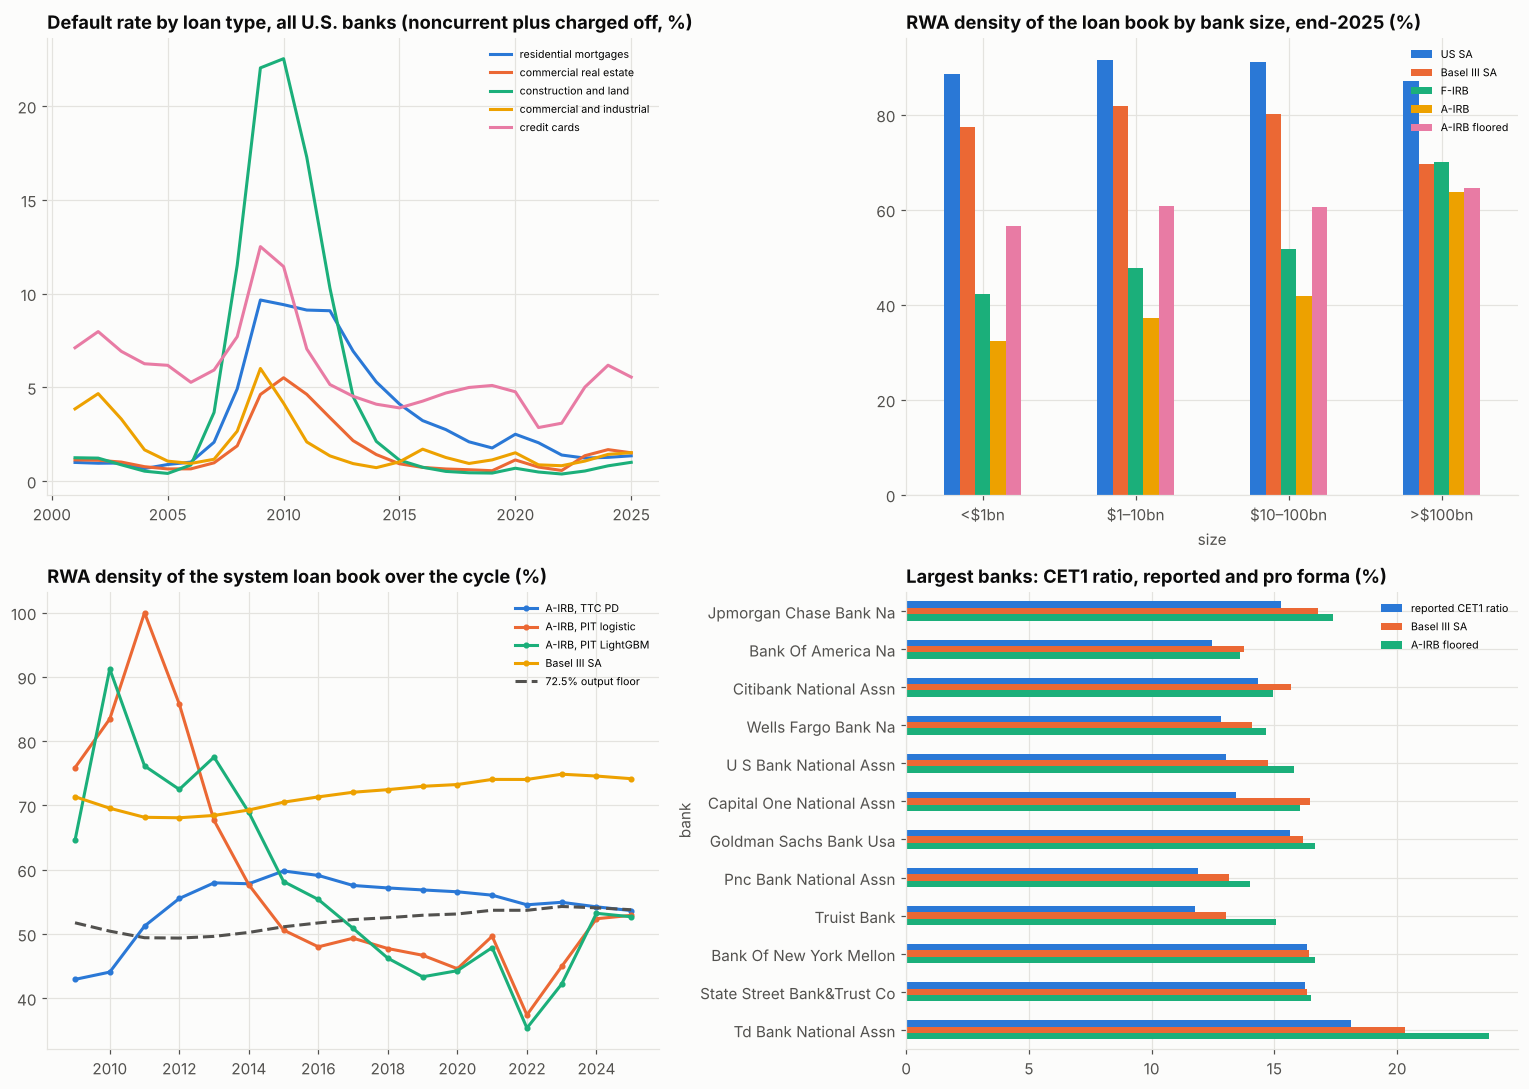

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
a = ax[0, 0]
for t, col in zip(
    [
        "residential mortgages",
        "commercial real estate",
        "construction and land",
        "commercial and industrial",
        "credit cards",
    ],
    PALETTE,
):
    a.plot(DR_SYS.index, DR_SYS[t] * 100, color=col, label=t)
a.set_title(
    "Default rate by loan type, all U.S. banks (noncurrent plus charged"
    " off, %)"
)
a.legend(fontsize=7)
a = ax[0, 1]
DENSITY.drop("all banks")[
    ["US SA", "Basel III SA", "F-IRB", "A-IRB", "A-IRB floored"]
].mul(100).plot.bar(ax=a, color=PALETTE[:5], rot=0)
a.set_title(f"RWA density of the loan book by bank size, end-{last} (%)")
a.legend(fontsize=7)
a = ax[1, 0]
for c, col in zip(
    [
        "A-IRB, TTC PD",
        "A-IRB, PIT logistic",
        "A-IRB, PIT LightGBM",
        "Basel III SA",
    ],
    PALETTE,
):
    a.plot(CYC.index, CYC[c] * 100, marker="o", ms=3, color=col, label=c)
a.plot(
    CYC.index,
    CYC["Basel III SA"] * 100 * FLOOR,
    ls="--",
    color=INK_2,
    label="72.5% output floor",
)
a.set_title("RWA density of the system loan book over the cycle (%)")
a.legend(fontsize=7)
a = ax[1, 1]
p = (
    PRO.head(12).set_index("bank")[
        ["reported CET1 ratio", "Basel III SA", "A-IRB floored"]
    ]
    * 100
)
p.plot.barh(ax=a, color=PALETTE[:3])
a.invert_yaxis()
a.set_title("Largest banks: CET1 ratio, reported and pro forma (%)")
a.legend(fontsize=7)
fig.tight_layout()
save_fig(fig, "01_credit_capital")
plt.show()

In [10]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        (
            "Out-of-time error of next-year default-rate forecasts"
            " (loan-weighted MAE, pts)"
        ),
        "Share of banks where the output floor binds",
        "Estimated LGD by loan type",
        "Realised system default rate vs IRB RWA density",
    ),
)
for m, col in zip(MODELS, PALETTE):
    dash.add_trace(
        go.Scatter(
            x=BY_YEAR.index, y=BY_YEAR[f"MAE {m}"], name=m, line_color=col
        ),
        1,
        1,
    )
dash.add_trace(
    go.Bar(
        x=BIND.index,
        y=BIND.values * 100,
        name="all banks",
        marker_color=PALETTE[1],
    ),
    1,
    2,
)
dash.add_trace(
    go.Bar(
        x=BIND_BIG.index,
        y=BIND_BIG.values * 100,
        name="banks over $100bn",
        marker_color=PALETTE[2],
    ),
    1,
    2,
)
dash.add_trace(
    go.Bar(
        x=LGD_EST.index,
        y=LGD_EST.values * 100,
        name="LGD",
        marker_color=PALETTE[3],
    ),
    2,
    1,
)
dash.add_trace(
    go.Scatter(
        x=CYC.index, y=CYC["realised default rate"] * 100, name="default rate"
    ),
    2,
    2,
)
dash.add_trace(
    go.Scatter(
        x=CYC.index,
        y=CYC["A-IRB, PIT LightGBM"] * 100,
        name="A-IRB PIT LightGBM density",
    ),
    2,
    2,
)
dash.update_layout(
    height=950,
    width=1400,
    template="simple_white",
    barmode="group",
    title=(
        "Basel III credit capital for U.S. banks: standardised, IRB and the"
        " output floor"
    ),
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 9. Reading the results and limitations

**The books and their risk.** At the end of 2025, 4,317 banks held \$11.0 trillion of loans. Measured as noncurrent plus charged-off loans, the long-run default rates from 2001 to 2025 and the estimated LGDs were:

| Loan type | Long-run default rate | Peak (year) | Estimated LGD |
|---|---|---|---|
| Credit cards | 5.9% | 12.5% (2009) | 71% |
| Construction and land | 4.2% | 22.5% (2010) | 22% |
| Residential mortgages | 3.4% | 9.7% (2009) | 12% |
| Other consumer | 2.6% | 5.0% (2011) | 61% |
| Home-equity lines | 2.2% | 5.0% (2012) | 34% |
| Commercial and industrial | 1.9% | 6.0% (2009) | 35% |
| Commercial real estate | 1.6% | 5.5% (2010) | 15% |
| Auto | 1.1% | 1.9% (2024) | 59% |
| Multifamily | 1.1% | 5.5% (2009) | 16% |

Construction lending had by far the worst crisis: almost a quarter of the book defaulted in 2010. Real-estate loans default often but lose little, because the collateral covers most of the debt. Unsecured consumer loans lose most of what defaults.

**Next year's default rate is best forecast by this year's.** Out of time, forecasting each year from 2009 to 2025 with models trained only on earlier years, on books of at least \$10 million:

| Forecast | Loan-weighted mean absolute error | Rank correlation | Average bias |
|---|---|---|---|
| Persistence | 1.07 pts | 0.73 | −0.07 pts |
| Fractional logistic regression | 3.54 pts | 0.72 | +2.94 pts |
| LightGBM | 1.66 pts | 0.63 | +0.74 pts |

All three rank banks almost equally well, because a book's current default rate already says most of what is known about next year's. The models fail on the level:
- **Logistic regression:** trained on data up to 2008, it extrapolated the crisis rise in unemployment and default rates and predicted a system default rate above 40% for 2010, when the actual rate was 8%; it overshot again for 2011 and 2012.
- **LightGBM:** cannot extrapolate beyond the range it has seen, so it is less extreme, but it still overpredicted by 5 points for 2010 and by 3–5 points for 2013–2014, after the crisis had passed.
- **From 2017:** with calmer data, the three are close (errors of 0.4–0.9 points).

**Credit RWA by approach.** RWA as a share of loans (density) at the end of 2025:

| Banks | U.S. standardised | Basel III SA-CR | F-IRB | A-IRB (TTC PD) | A-IRB (PIT, LightGBM) | A-IRB with the 72.5% floor |
|---|---|---|---|---|---|---|
| Under \$1bn | 89% | 77% | 42% | 33% | 30% | 57% |
| \$1–10bn | 92% | 82% | 48% | 37% | 34% | 61% |
| \$10–100bn | 91% | 80% | 52% | 42% | 39% | 61% |
| Over \$100bn | 87% | 70% | 70% | 64% | 58% | 65% |
| All banks | 89% | 74% | 61% | 53% | 48% | 63% |

- **SA-CR is lighter than today's U.S. rules** for loans: \$8.2 trillion of RWA instead of \$9.8 trillion. The main reasons are a 30% weight for mortgages instead of 50%, and 75–85% for retail and small-business loans instead of 100%. The 2023 U.S. proposal set some of these weights higher than Basel's and raised capital mainly through operational and market risk, which are outside this loan-book exercise.
- **IRB would cut credit RWA by half or more for small banks.** Their books are dominated by real estate, with low LGDs, so the floor binds for 94% of all banks under A-IRB. For banks over \$100 billion it binds for 35% (23% under F-IRB): their credit-card and C&I books carry IRB weights close to or above the standardised ones.
- **Point-in-time PDs lower RWA today** (density 48% against 53% with long-run averages), because default rates in 2025 are below their 25-year average, which includes the crisis.

**The largest banks.** For the 31 banks over \$100 billion, the loan book is 49% of reported RWA. Replacing its U.S. standardised RWA would change their aggregate CET1 ratio as follows:
- 14.1% today;
- 15.6% under SA-CR;
- 15.5% under F-IRB with the floor;
- 16.1% under A-IRB with the floor;
- 16.7% with LightGBM point-in-time PDs.

Card lenders are the exception: American Express and Synchrony would hold more capital under IRB than under SA-CR, because their high default rates and LGDs give IRB weights above the 75% retail weight.

**Point-in-time PDs make capital highly procyclical.** RWA density of the system loan book, with the PD known at each date:

| Year | Realised default rate | A-IRB, long-run PD | A-IRB, PIT logistic | A-IRB, PIT LightGBM | SA-CR |
|---|---|---|---|---|---|
| 2009 | 8.7% | 43% | 76% | 65% | 71% |
| 2010 | 8.0% | 44% | 83% | 91% | 70% |
| 2011 | 6.8% | 51% | 100% | 76% | 68% |
| 2015 | 2.4% | 60% | 51% | 58% | 71% |
| 2022 | 1.2% | 55% | 37% | 35% | 74% |
| 2025 | 1.9% | 54% | 53% | 53% | 74% |

With point-in-time PDs, RWA density swung by 56–63 points between the crisis and 2022, so a bank would have needed almost three times as much capital in 2011 as in 2022 for the same loans. Capital peaked in 2010–2011, a year or two after defaults peaked, and was lowest in 2022, just before rates rose and commercial real-estate losses began. Long-run average PDs swung by 17 points. They rose after the crisis, as the crisis years entered the average, and then drifted down slowly. The 72.5% floor on SA-CR (about 49–54% of loans) would have bound in the good years with point-in-time PDs and limited how far capital could fall. That is one of its purposes.

**What this means for capital planning.**
- **Who gains from models:** for most U.S. banks, internal models would lower credit capital far below the standardised level, and the output floor would decide their capital. The floor matters for regional and community banks with real-estate books more than for the largest banks.
- **Choice of PD model:** it changes capital most through cyclicality, not through ranking. Gradient boosting does not beat persistence in ranking default risk, and both machine-learning models overshot in the crisis. Through-the-cycle PDs, or point-in-time PDs with a downturn adjustment, are needed for stable capital.
- **Card-heavy books:** IRB adds capital rather than saving it, and the SA-CR 75% retail weight understates their risk.

**Limitations.**
- **Default and LGD proxies:** defaults are proxied by noncurrent loans plus net charge-offs, and LGD by charge-offs relative to that measure. Recoveries after charge-off, restructured loans that stay current, and differences in charge-off policies between banks are not captured. LGDs are pooled by loan type rather than estimated per bank, and are not downturn LGDs.
- **Coverage:** only on-balance-sheet loans are included. Undrawn commitments, securities, derivatives, counterparty, market and operational risk are excluded, as are the U.S. proposal's specific weights (for example, higher residential weights).
- **Standardised weights:** the call report has no loan-to-value data, so all mortgages get the 60–80% LTV weight, all CRE 100% and all C&I the SME corporate weight; investment-grade corporates would get 65%.
- **IRB inputs:** one maturity of 2.5 years for corporates, no EAD modelling, and no margin of conservatism. Real IRB models are built on loan-level data with rating grades, not on bank-level aggregates.

In [11]:
TABLE.to_csv(OUT_DIR / "default_rates_and_lgd_by_type.csv")
BY_YEAR.to_csv(OUT_DIR / "pd_forecast_scores_by_year.csv")
DENSITY.to_csv(OUT_DIR / "rwa_density_by_size.csv")
B.to_csv(OUT_DIR / "bank_level_rwa.csv", index=False)
PRO.to_csv(OUT_DIR / "largest_banks_pro_forma_cet1.csv", index=False)
CYC.to_csv(OUT_DIR / "rwa_density_through_the_cycle.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_credit_capital.png, bank_level_rwa.csv, dashboard.html, dashboard.png, default_rates_and_lgd_by_type.csv, largest_banks_pro_forma_cet1.csv, pd_forecast_scores_by_year.csv, rwa_density_by_size.csv, rwa_density_through_the_cycle.csv


## References

### Finance and regulation

- Basel Committee on Banking Supervision. (2017). *Basel III: Finalising post-crisis reforms*. Bank for International Settlements. https://www.bis.org/bcbs/publ/d424.htm
- Basel Committee on Banking Supervision. (2005). *An explanatory note on the Basel II IRB risk weight functions*. Bank for International Settlements. https://www.bis.org/bcbs/irbriskweight.htm
- Board of Governors of the Federal Reserve System, Federal Deposit Insurance Corporation, & Office of the Comptroller of the Currency. (2023). Regulatory capital rule: Large banking organizations and banking organizations with significant trading activity. *Federal Register, 88*, 64028. https://www.federalregister.gov/documents/2023/09/18/2023-19200
- Gordy, M. B. (2003). A risk-factor model foundation for ratings-based bank capital rules. *Journal of Financial Intermediation, 12*(3), 199–232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Repullo, R., & Suarez, J. (2013). The procyclical effects of bank capital regulation. *The Review of Financial Studies, 26*(2), 452–490. https://doi.org/10.1093/rfs/hhs118
- Federal Deposit Insurance Corporation. (2026). *BankFind Suite: Financial data API* [Data set]. https://api.fdic.gov/banks/docs/

### Machine learning and econometrics

- Papke, L. E., & Wooldridge, J. M. (1996). Econometric methods for fractional response variables with an application to 401(k) plan participation rates. *Journal of Applied Econometrics, 11*(6), 619–632. https://doi.org/10.1002/(SICI)1099-1255(199611)11:6<619::AID-JAE418>3.0.CO;2-1
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html